# Lost and Found: Logistic Regression base model (CAT 2)

**AI Application: Classification**  
**Algorithm/Approach: Logistic Regression**

We classify a pair containing one lost report and one found report: `1 = match`, `0 = non-match`. The probability can later sort candidate found reports in the mobile application. It is a review signal, never proof of ownership. Staff must verify a claim before release.

Run this notebook from the `AI-project` repository root, top to bottom. The campus inputs are checked in. For the Delhi exploration, first obtain the CSV using `docs/DATASET.md` and put it at `data/raw/delhi/delhimetrorail.csv`; Git ignores that local file because descriptions may contain personal details. The existing `matching_system_testing.ipynb` is a separate engineering notebook.


## 1. Sources and the question

* **Synthetic campus reports (46):** lost and found reports used for the classifier.
* **Labelled campus pairs (32):** examples connecting a lost report to a found report.
* **Delhi Metro:** a locally supplied CSV used for data-quality exploration only. It has no verified lost/found pair labels and cannot measure matching accuracy.
* **Images:** no downloaded or paired same-item images in this repository; CLIP is future work.

The current rule-based ranker remains a comparison baseline. It has manually chosen weights and is **not** the trained CAT 2 model.


In [1]:
from pathlib import Path
from collections import Counter
import csv
import json
import pandas as pd

from matching_system.normalization import normalize_text
from matching_system.data_loader import load_reports
from matching_system.matcher import score_pair
from scripts.prepare_campus_data import prepare as prepare_campus
from scripts.prepare_delhi_data import prepare as prepare_delhi
from scripts.build_modelling_pairs import build as build_pairs
from scripts.split_campus_data import split
from matching_system.ml_model import run_experiment

ROOT = Path.cwd()
assert (ROOT / 'matching_system').is_dir(), 'Open this notebook from the AI-project root'
try:
    import matplotlib.pyplot as plt
except ModuleNotFoundError:
    plt = None
    print('Matplotlib is unavailable here; numeric EDA and modelling still run. Install requirements.txt to create figures.')


## 2. Initial exploration of untouched data

The campus source has six rows with an extra empty CSV field. We inspect them with `csv.DictReader` rather than letting a parser silently discard rows. `None` is the overflow column created by the malformed records.


In [2]:
campus_path = ROOT / 'data/raw/campus/synthetic_campus_reports.csv'
labels_path = ROOT / 'data/raw/campus/labelled_campus_pairs.csv'
delhi_path = ROOT / 'data/raw/delhi/delhimetrorail.csv'
with campus_path.open(encoding='utf-8', newline='') as handle:
    reader = csv.DictReader(handle)
    raw_columns = reader.fieldnames
    raw_records = list(reader)
malformed = [row['report_id'] for row in raw_records if row.get(None) is not None]
raw_campus = pd.DataFrame([{name: row[name] for name in raw_columns} for row in raw_records]).replace('', pd.NA)
labels = pd.read_csv(labels_path)
delhi = pd.read_csv(delhi_path)
print('Raw campus shape:', raw_campus.shape)
print('Columns:', raw_campus.columns.tolist())
print('Data types:\n', raw_campus.dtypes.to_string())
print('Raw campus missing values:\n', raw_campus.isna().sum().to_string())
print('Duplicate campus rows:', raw_campus.duplicated().sum())
print('Malformed report IDs:', malformed)
print('Affected raw fields:\n', raw_campus.loc[raw_campus.report_id.isin(malformed), ['report_id','category','colour','material']].to_string(index=False))
print('\nFirst campus rows:\n', raw_campus.head(3).to_string(index=False))
print('\nLabel counts:\n', labels['label'].value_counts().to_string())
print('\nDelhi shape:', delhi.shape)
print('Delhi missing values:\n', delhi.isna().sum().to_string())
print('Delhi exact duplicate rows:', delhi.duplicated().sum())


Raw campus shape: (46, 13)
Columns: ['report_id', 'report_type', 'description', 'category', 'brand', 'model', 'colour', 'material', 'distinctive_features', 'location', 'reported_at', 'status', 'image_reference']
Data types:
 report_id               str
report_type             str
description             str
category                str
brand                   str
model                   str
colour                  str
material                str
distinctive_features    str
location                str
reported_at             str
status                  str
image_reference         str
Raw campus missing values:
 report_id                0
report_type              0
description              0
category                 0
brand                   29
model                   35
colour                   9
material                 0
distinctive_features     7
location                 0
reported_at              0
status                   0
image_reference         40
Duplicate campus rows: 0
Malform

## 3. Clean without changing raw files

The existing campus preparation script fixes only the six shifted rows in a generated copy. The Delhi preparation script trims repeated whitespace, creates normalized text/date columns, and records missing values; it does not remove records. We verify row counts and corrected fields afterward. Missing brand or model is **unknown**, not evidence of a contradiction.


In [3]:
campus_correction = prepare_campus()
delhi_audit = prepare_delhi()
campus = pd.read_csv(ROOT / 'data/processed/synthetic_campus_reports.csv')
print('Campus cleaning:', campus_correction)
print('Raw/clean campus rows:', len(raw_campus), len(campus))
print('Corrected umbrella fields:\n', campus.loc[campus.report_id == 'found-015', ['report_id','category','colour','material']].to_string(index=False))
print('Clean campus missing values:\n', campus.isna().sum().to_string())
print('Clean campus duplicate IDs:', campus.report_id.duplicated().sum())
print('Delhi retained rows:', delhi_audit['original_rows'], delhi_audit['final_rows'])
print('Delhi missing values:', delhi_audit['missing_values'])
assert len(raw_campus) == len(campus) == 46
assert campus.report_id.is_unique
assert delhi_audit['original_rows'] == delhi_audit['final_rows']


Campus cleaning: {'source_rows': 46, 'output_rows': 46, 'repaired_ids': ['lost-006', 'found-015', 'found-016', 'lost-010', 'found-023', 'found-024']}
Raw/clean campus rows: 46 46
Corrected umbrella fields:
 report_id category colour material
found-015 umbrella  black      NaN
Clean campus missing values:
 report_id                0
report_type              0
description              0
category                 0
brand                   29
model                   35
colour                   3
material                 2
distinctive_features     5
location                 0
reported_at              0
status                   0
image_reference         46
Clean campus duplicate IDs: 0
Delhi retained rows: 13713 13713
Delhi missing values: {'item_quantity': 10511, 'description': 8208}


### Wording normalization

Two people can describe the same detail differently (`blk`/`black`, `grey`/`gray`, `school bag`/`backpack`). The feature builder reuses the project's normalization function so these differences do not automatically look like different items. It does not fill missing fields with guessed values.


In [4]:
for phrase in ['blk school bag', 'grey USB-C charger', 'black backpack']:
    print(f'{phrase!r} -> {normalize_text(phrase)!r}')


'blk school bag' -> 'black backpack'
'grey USB-C charger' -> 'gray usb c charger'
'black backpack' -> 'black backpack'


## 4. Exploratory data analysis (EDA)

These four observations are generated from the actual files at run time. Counts for the synthetic campus examples describe our **designed sample**; Delhi counts describe the external found-item dataset. They do not establish real Strathmore prevalence.


In [5]:
report_counts = campus.report_type.value_counts()
category_counts = campus.category.value_counts()
label_counts = labels.label.value_counts()
missing_optional = campus[['brand','model','material']].isna().sum()
delhi_missing = delhi[['description','item_quantity']].isna().sum()
print('Campus report types:\n', report_counts.to_string())
print('Campus top categories:\n', category_counts.head(8).to_string())
print('Missing optional campus fields:\n', missing_optional.to_string())
print('Pair labels:\n', label_counts.to_string())
print('Delhi top item names:\n', delhi.item_name.value_counts().head(8).to_string())
print('Delhi top stations:\n', delhi.station_name.value_counts().head(8).to_string())
print('Delhi missing fields:\n', delhi_missing.to_string())
print('\nKey EDA observations:')
print(f'1. Campus reports: {report_counts.get("found",0)} found vs {report_counts.get("lost",0)} lost. A lost report must be compared with several candidates.')
print(f'2. Optional fields are incomplete: {missing_optional["brand"]} lack brand and {missing_optional["model"]} lack model. The model needs multiple signals and missing values must not be treated as disagreement.')
print(f'3. The pair set has {label_counts.get("match",0)} matches, {label_counts.get("plausible",0)} plausible cases, and {label_counts.get("non_match",0)} clear non-matches. Plausible cases test similar-looking distractors.')
print(f'4. Delhi has {delhi_missing["description"]}/{len(delhi)} missing descriptions and {delhi_missing["item_quantity"]}/{len(delhi)} missing quantities. Real-world data quality limits text-only signals.')


Campus report types:
 report_type
found    32
lost     14
Campus top categories:
 category
backpack        4
laptop          4
phone           4
water bottle    4
wallet          3
umbrella        3
earbuds         3
notebook        3
Missing optional campus fields:
 brand       29
model       35
material     2
Pair labels:
 label
match        14
non_match    10
plausible     8
Delhi top item names:
 item_name
BAG          1554
PURSE         756
BOTTLE        700
LUNCH BOX     530
CASH          499
POLY BAG      494
WATCH         431
HELMET        362
Delhi top stations:
 station_name
KASHMERE GATE                        702
NEW DELHI (Yellow & Airport Line)    701
RAJIV CHOWK                          630
AIRPORT (T-3)                        587
SAMAYPUR BADLI                       475
DWARKA SECTOR - 21                   466
RITHALA                              334
MILLENNIUM CITY CENTRE GURUGRAM      326
Delhi missing fields:
 description       8208
item_quantity    10511

Key EDA ob

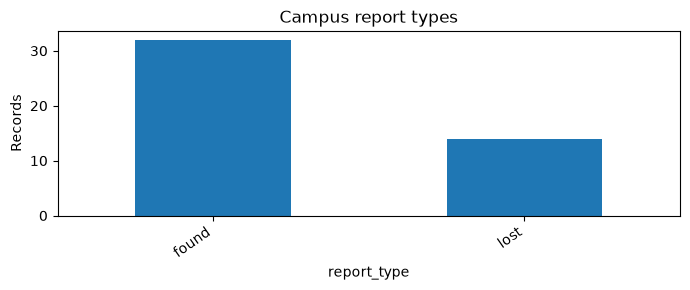

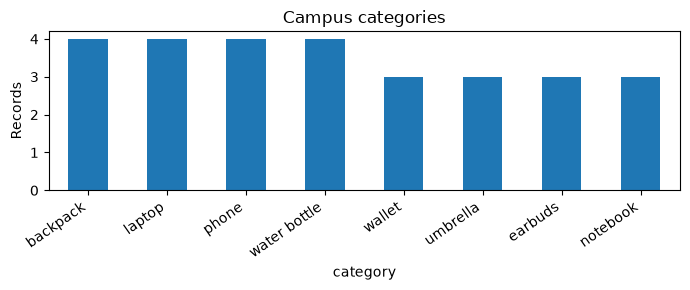

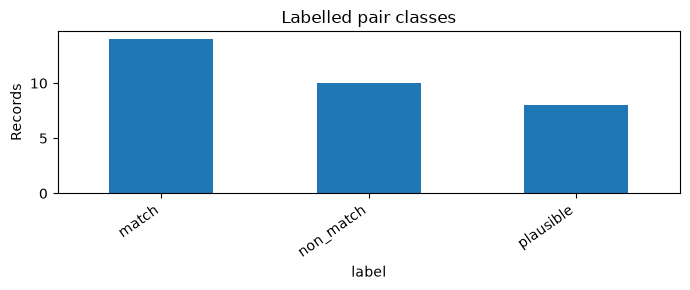

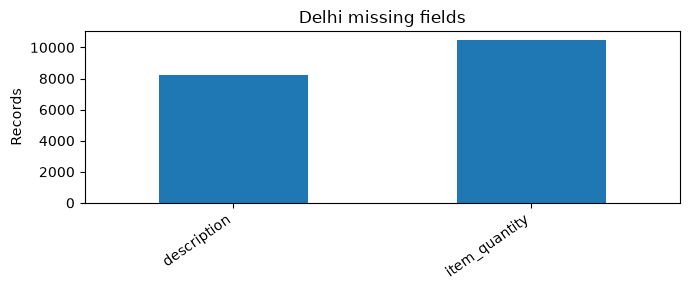

Figures saved in C:\Users\HP\Documents\ChatGPT\Lost and Found system\AI-project\results\figures
Interpretation: the campus sample has multiple found candidates per lost report; optional fields and Delhi descriptions are often missing. The plausible labels make superficially similar pairs an explicit challenge. These observations motivate combining several features rather than trusting one field.


In [6]:
if plt is not None:
    figures = ROOT / 'results/figures'
    figures.mkdir(parents=True, exist_ok=True)
    for title, series, filename in [
        ('Campus report types', report_counts, 'report_types.png'),
        ('Campus categories', category_counts.head(8), 'categories.png'),
        ('Labelled pair classes', label_counts, 'pair_labels.png'),
        ('Delhi missing fields', delhi_missing, 'delhi_missing.png'),
    ]:
        ax = series.plot.bar(title=title, figsize=(7, 3))
        ax.set_ylabel('Records')
        plt.xticks(rotation=35, ha='right')
        plt.tight_layout()
        plt.savefig(figures / filename, dpi=150)
        plt.show()
        plt.close()
    print('Figures saved in', figures)
else:
    print('Figure creation pending Matplotlib installation; the underlying counts and observations appear above.')
print('Interpretation: the campus sample has multiple found candidates per lost report; optional fields and Delhi descriptions are often missing. The plausible labels make superficially similar pairs an explicit challenge. These observations motivate combining several features rather than trusting one field.')


## 5. Feature engineering and final modelling table

One row represents **one labelled lost/found pair**. Description, location and distinctive-feature similarity use normalized word overlap. For category, colour, brand, model and material we record separate match and conflict flags; missing values set both flags to zero. Time distance is capped at 48 hours. The output is `data/processed/modelling_pairs.csv`.

For this CAT 2 experiment: `match -> 1`, `plausible -> 0`, `non_match -> 0`. Treating `plausible` as class 0 follows the coursework design, **but an unconfirmed pair is not independently verified as a different physical item**. We check sensitivity with those rows excluded later.


In [7]:
pair_build = build_pairs()
model_table = pd.read_csv(ROOT / 'data/processed/modelling_pairs.csv')
print(pair_build)
print('Modelling columns:', model_table.columns.tolist())
print('Target distribution:\n', model_table.target.value_counts().to_string())
print(model_table.head(5).to_string(index=False))
X = model_table.drop(columns=['lost_report_id','found_report_id','original_label','target'])
y = model_table['target']
print('X =', X.shape, 'numeric feature values; y =', y.shape, 'binary labels')
assert X.notna().all().all()


{'rows': 32, 'labels': {'match': 14, 'plausible': 8, 'non_match': 10}, 'targets': {1: 14, 0: 18}, 'raw_corrections': {'source_rows': 46, 'output_rows': 46, 'repaired_ids': ['lost-006', 'found-015', 'found-016', 'lost-010', 'found-023', 'found-024']}, 'output': 'C:\\Users\\HP\\Documents\\ChatGPT\\Lost and Found system\\AI-project\\data\\processed\\modelling_pairs.csv'}
Modelling columns: ['lost_report_id', 'found_report_id', 'original_label', 'description_similarity', 'category_match', 'category_conflict', 'colour_match', 'colour_conflict', 'brand_match', 'brand_conflict', 'model_match', 'model_conflict', 'material_match', 'material_conflict', 'distinctive_feature_similarity', 'location_similarity', 'time_difference_hours', 'target']
Target distribution:
 target
0    18
1    14
lost_report_id found_report_id original_label  description_similarity  category_match  category_conflict  colour_match  colour_conflict  brand_match  brand_conflict  model_match  model_conflict  material_match  m

## 6. Training and validation

Logistic regression learns a coefficient for each numeric feature and turns their weighted sum into a score between 0 and 1. A `0.5` threshold gives a binary prediction for this baseline; the output is **not calibrated proof of ownership**.

We use the fixed group split: 10 lost reports/24 pairs for development and 4 lost reports/8 pairs for a held-out check. Within development, `GroupKFold` keeps all candidates for a lost report together. The scaler is fitted inside each training fold. Invalid single-class folds would be skipped rather than reported as valid. The old rule-based work predates this split, and these synthetic examples were designed for matching, so this is not an independent field test.


In [8]:
manifest = split()
print('Grouped split:', {name: {'lost_reports':len(part['lost_ids']), 'pairs':part['pair_count']} for name, part in manifest['splits'].items()})
result = run_experiment(ROOT / 'data/processed/modelling_pairs.csv', ROOT / 'data/processed/campus_split.json', ROOT / 'results/ml')
folds = pd.DataFrame(result['grouped_cv'])
print('Grouped development validation:\n', folds[['fold','train_pairs','validation_pairs','precision','recall','f1']].to_string(index=False))
print('Held-out test:', result['held_out_test'])
print('Excluding plausible labels:', result['plausible_excluded_sensitivity'])


Grouped split: {'development': {'lost_reports': 10, 'pairs': 24}, 'test': {'lost_reports': 4, 'pairs': 8}}


Grouped development validation:
  fold  train_pairs  validation_pairs  precision  recall       f1
    1           19                 5   0.500000     1.0 0.666667
    2           19                 5   0.666667     1.0 0.800000
    3           19                 5   1.000000     0.5 0.666667
    4           19                 5   1.000000     1.0 1.000000
    5           20                 4   0.666667     1.0 0.800000
Held-out test: {'precision': 1.0, 'recall': 0.75, 'f1': 0.8571428571428571, 'confusion_matrix': [[4, 0], [1, 3]], 'roc_auc': 1.0}
Excluding plausible labels: {'development_pairs': 18, 'test_pairs': 6, 'precision': 1.0, 'recall': 1.0, 'f1': 1.0, 'confusion_matrix': [[2, 0], [0, 4]], 'roc_auc': 1.0}


## 7. Evaluation, errors and interpretation

Precision asks what fraction of predicted matches were labelled matches. Recall asks what fraction of labelled matches were found. F1 combines these. The confusion matrix uses rows `[actual non-match, actual match]` and columns `[predicted non-match, predicted match]`. ROC-AUC is reported only when both classes occur. With eight test pairs, all metrics are unstable and must not be advertised as campus accuracy.


In [9]:
predictions = pd.read_csv(ROOT / 'results/ml/test_predictions.csv')
errors = predictions[predictions.target != predictions.predicted_class]
print('Test predictions:\n', predictions.to_string(index=False))
print('Classification errors:\n', errors.to_string(index=False) if len(errors) else 'None in this split')
print('Plausible cases in test:\n', predictions[predictions.original_label == 'plausible'].to_string(index=False))
print('Confusion matrix [[TN, FP], [FN, TP]]:', result['held_out_test']['confusion_matrix'])
reports_for_errors = {row.report_id: row for row in load_reports(ROOT / 'data/processed/synthetic_campus_reports.csv')}
for row in errors.itertuples():
    print('\nError:', row.lost_report_id, row.found_report_id, 'probability', round(row.match_probability, 3))
    print('Lost:', reports_for_errors[row.lost_report_id].description)
    print('Found:', reports_for_errors[row.found_report_id].description)
    pair_row = model_table[(model_table.lost_report_id == row.lost_report_id) & (model_table.found_report_id == row.found_report_id)]
    print('Relevant features:', pair_row.drop(columns=['lost_report_id','found_report_id','original_label','target']).iloc[0].to_dict())


Test predictions:
 lost_report_id found_report_id original_label  target  match_probability  predicted_class
      lost-007       found-017          match       1           0.986894                1
      lost-007       found-018      plausible       0           0.416830                0
      lost-008       found-019          match       1           0.911090                1
      lost-008       found-020      plausible       0           0.393021                0
      lost-009       found-021          match       1           0.445390                0
      lost-009       found-022      non_match       0           0.109528                0
      lost-013       found-029          match       1           0.998419                1
      lost-013       found-030      non_match       0           0.181367                0
Classification errors:
 lost_report_id found_report_id original_label  target  match_probability  predicted_class
      lost-009       found-021          match       1    

In [10]:
coefficients = pd.read_csv(ROOT / 'results/ml/coefficients.csv')
print(coefficients.to_string(index=False))
print('These are coefficients after StandardScaler; a sign shows direction in this fitted synthetic model, not a causal effect.')
print('If a coefficient has a surprising sign, such as location overlap, treat it as a warning about this tiny, correlated sample rather than a campus-wide relationship.')


                       feature  standardized_coefficient
distinctive_feature_similarity                  0.804309
                  colour_match                  0.753903
        description_similarity                  0.680827
                   model_match                  0.460151
                   brand_match                  0.177038
                category_match                  0.000000
             category_conflict                  0.000000
                material_match                 -0.077807
                brand_conflict                 -0.408513
           location_similarity                 -0.444292
                model_conflict                 -0.448358
             material_conflict                 -0.552429
               colour_conflict                 -0.753903
         time_difference_hours                 -0.912632
These are coefficients after StandardScaler; a sign shows direction in this fitted synthetic model, not a causal effect.
If a coefficient has a s

### Rule-based comparison on the same labelled test candidates

This is a small *ranking* check, separate from classification precision/recall/F1. We compare which labelled candidate each method puts first per test lost report. Unlabelled candidates are excluded because their true relationships are unknown. The rule baseline is not trained ML.


In [11]:
reports_by_id = {report.report_id: report for report in load_reports(ROOT / 'data/processed/synthetic_campus_reports.csv')}
comparison = predictions.copy()
comparison['rule_score'] = [score_pair(reports_by_id[row.lost_report_id], reports_by_id[row.found_report_id]).score for row in comparison.itertuples()]
for lost_id, group in comparison.groupby('lost_report_id'):
    ml_top = group.sort_values('match_probability', ascending=False).iloc[0]
    rule_top = group.sort_values('rule_score', ascending=False).iloc[0]
    print(lost_id, 'ML top:', ml_top.found_report_id, ml_top.original_label,
          '| rule top:', rule_top.found_report_id, rule_top.original_label)
print('This labelled-candidate check is not a full application ranking evaluation.')


lost-007 ML top: found-017 match | rule top: found-017 match
lost-008 ML top: found-019 match | rule top: found-019 match
lost-009 ML top: found-021 match | rule top: found-021 match
lost-013 ML top: found-029 match | rule top: found-029 match
This labelled-candidate check is not a full application ranking evaluation.


## 8. Further validation and next steps

For the course's further-validation question, the team can later compare **Random Forest** and **Support Vector Machine** against this Logistic Regression base model using the *same feature table, grouped split, and metrics*. No results for those future models are claimed here. Collect more independently reviewed real-campus pairs, keep whole physical items together across splits, and assess robustness to missing or ambiguous details.

Future image work requires photographs with `instance_id` labels for the same physical item. The external Roboflow object-detection dataset has category boxes, not same-item pairs. Frozen CLIP embeddings could later add image similarity as a feature; compare text-only and text-plus-image on a truly paired dataset. The mobile app and current API do **not** run this classifier yet. A human must verify ownership.
